In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

!nvidia-smi

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Fri Oct 23 05:58:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                              

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Kannada_Digit_Recognition"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Google Drive connected successfully.")
print("Project folder:", PROJECT_DIR)

Google Drive connected successfully.
Project folder: /content/drive/MyDrive/Kannada_Digit_Recognition


In [ ]:
!pip -q install -U kaggle

from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle token loaded successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.2/140.2 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.9/290.9 kB 24.8 MB/s eta 0:00:00
Kaggle token loaded successfully.


In [ ]:
!kaggle competitions files -c Kannada-MNIST

name                         size  creationDate                
---------------------  ----------  --------------------------  
Dig-MNIST.csv            18401187  2019-09-16 22:41:08.034000  
sample_submission.csv       33899  2019-09-16 22:41:07.605000  
test.csv                  8667163  2019-09-16 22:41:07.446000  
train.csv               104748945  2019-09-16 22:41:11.071000  


In [ ]:
!mkdir -p /content/kannada_data

!kaggle competitions download -c Kannada-MNIST -p /content/kannada_data

!ls -lh /content/kannada_data

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFiles

You don't have access to this resource.
If this is a competition, you may need to accept its rules first at
  https://www.kaggle.com/competitions/<competition>/rules
total 0


In [ ]:
!rm -rf /content/kannada_data
!mkdir -p /content/kannada_data

!kaggle datasets download -d higgstachyon/kannada-mnist -p /content/kannada_data

!ls -lh /content/kannada_data

Dataset URL: https://www.kaggle.com/datasets/higgstachyon/kannada-mnist
License(s): copyright-authors
100% 20.8M/20.8M [00:00<00:00, 84.1MB/s]

total 21M
-rw-r--r-- 1 root root 21M Aug  4  2019 kannada-mnist.zip


In [ ]:
!unzip -o /content/kannada_data/kannada-mnist.zip -d /content/kannada_data/extracted

!find /content/kannada_data/extracted -type f | head -50

Archive:  /content/kannada_data/kannada-mnist.zip
  inflating: /content/kannada_data/extracted/Kannada_MNIST_datataset_paper/Kannada_MNIST_Ubyte_gz/Dig_MNIST/X_dig_MNIST-idx3-ubyte/  (         
  inflating: /content/kannada_data/extracted/Kannada_MNIST_datataset_paper/Kannada_MNIST_Ubyte_gz/Dig_MNIST/y_dig_MNIST-idx1-ubyte/y_dig_MNIST-idx1-ubyte  
  inflating: /content/kannada_data/extracted/Kannada_MNIST_datataset_paper/Kannada_MNIST_Ubyte_gz/Kannada_MNIST/X_kannada_MNIST_test-idx3-ubyte/  '        
  inflating: /content/kannada_data/extracted/Kannada_MNIST_datataset_paper/Kannada_MNIST_Ubyte_gz/Kannada_MNIST/X_kannada_MNIST_test-idx3-ubyte/qтХЮ  cтХа┬а                    тХЮ   U┬а                    ├Ц┬▒тХЮ   U┬а                    ┬м┬╗  
  inflating: /content/kannada_data/extracted/Kannada_MNIST_datataset_paper/Kannada_MNIST_Ubyte_gz/Kannada_MNIST/X_kannada_MNIST_train-idx3-ubyte/  ╬й`        
  inflating: /content/kannada_data/extracted/Kannada_MNIST_datataset_paper/Kannada_MNIST_U

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

BASE_PATH = "/content/kannada_data/extracted/Kannada_MNIST_datataset_paper/Kannada_MNIST_npz"

X_train_path = f"{BASE_PATH}/Kannada_MNIST/X_kannada_MNIST_train.npz"
y_train_path = f"{BASE_PATH}/Kannada_MNIST/y_kannada_MNIST_train.npz"

X_test_path = f"{BASE_PATH}/Kannada_MNIST/X_kannada_MNIST_test.npz"
y_test_path = f"{BASE_PATH}/Kannada_MNIST/y_kannada_MNIST_test.npz"

X_dig_path = f"{BASE_PATH}/Dig_MNIST/X_dig_MNIST.npz"
y_dig_path = f"{BASE_PATH}/Dig_MNIST/y_dig_MNIST.npz"

X_train = np.load(X_train_path)["arr_0"]
y_train = np.load(y_train_path)["arr_0"]

X_test = np.load(X_test_path)["arr_0"]
y_test = np.load(y_test_path)["arr_0"]

X_dig = np.load(X_dig_path)["arr_0"]
y_dig = np.load(y_dig_path)["arr_0"]

print("Kannada-MNIST training images:", X_train.shape)
print("Kannada-MNIST training labels:", y_train.shape)

print("Kannada-MNIST standard test images:", X_test.shape)
print("Kannada-MNIST standard test labels:", y_test.shape)

print("Dig-MNIST images:", X_dig.shape)
print("Dig-MNIST labels:", y_dig.shape)

print("Pixel range:", X_train.min(), "to", X_train.max())
print("Classes:", np.unique(y_train))

Kannada-MNIST training images: (60000, 28, 28)
Kannada-MNIST training labels: (60000,)
Kannada-MNIST standard test images: (10000, 28, 28)
Kannada-MNIST standard test labels: (10000,)
Dig-MNIST images: (10240, 28, 28)
Dig-MNIST labels: (10240,)
Pixel range: 0 to 255
Classes: [0 1 2 3 4 5 6 7 8 9]


In [ ]:
import tensorflow as tf

# Convert image values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_dig = X_dig.astype("float32") / 255.0

# Add grayscale channel: (N, 28, 28) -> (N, 28, 28, 1)
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)
X_dig = np.expand_dims(X_dig, axis=-1)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("X_dig shape:", X_dig.shape)

print("Normalized pixel range:", X_train.min(), "to", X_train.max())

X_train shape: (60000, 28, 28, 1)
X_test shape: (10000, 28, 28, 1)
X_dig shape: (10240, 28, 28, 1)
Normalized pixel range: 0.0 to 1.0


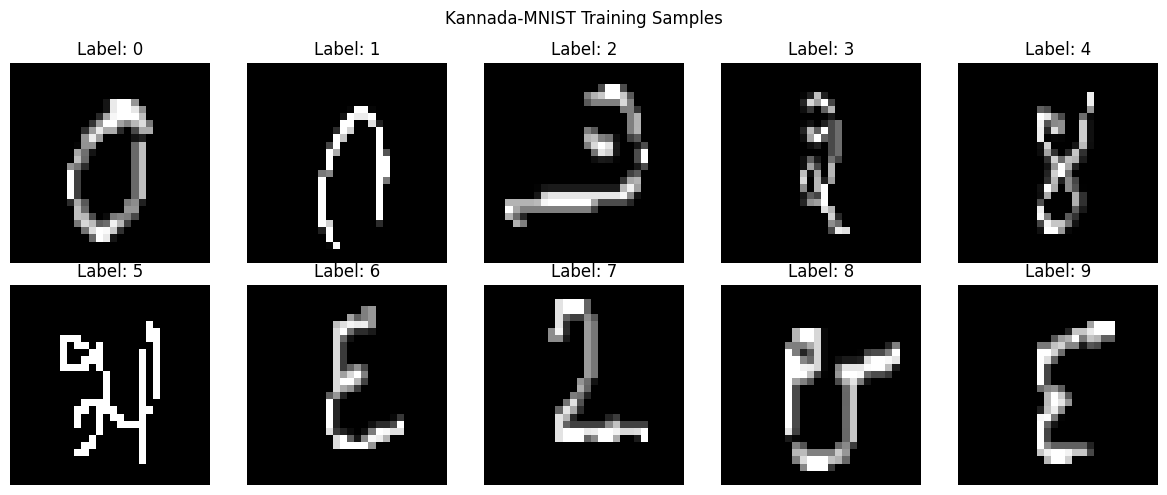

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Kannada-MNIST Training Samples")
plt.tight_layout()

plt.savefig(f"{PROJECT_DIR}/sample_training_images.png", dpi=300)
plt.show()

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dropout(0.30),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.30),

    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,442 (947.04 KB)

 Trainable params: 241,994 (945.29 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
from tensorflow.keras import callbacks

MODEL_PATH = f"{PROJECT_DIR}/best_kannada_cnn.keras"

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

model_checkpoint = callbacks.ModelCheckpoint(
    filepath=MODEL_PATH,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.10,
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping, model_checkpoint],
    verbose=1
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8743 - loss: 0.4363
Epoch 1: val_accuracy improved from None to 0.97933, saving model to /content/drive/MyDrive/Kannada_Digit_Recognition/best_kannada_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Kannada_Digit_Recognition/best_kannada_cnn.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 27ms/step - accuracy: 0.9509 - loss: 0.1622 - val_accuracy: 0.9793 - val_loss: 0.0676
Epoch 2/20
416/422 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9871 - loss: 0.0415
Epoch 2: val_accuracy improved from 0.97933 to 0.99183, saving model to /content/drive/MyDrive/Kannada_Digit_Recognition/best_kannada_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Kannada_Digit_Recognition/best_kannada_cnn.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9877 - loss: 0.0394 - val_accuracy: 0.9918 - val_loss: 0.0273
Epoch 3/20
417/422 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9906 - loss: 0.0291
Epoch 

In [ ]:
best_model = tf.keras.models.load_model(
    f"{PROJECT_DIR}/best_kannada_cnn.keras"
)

print("Best saved model loaded successfully.")

Best saved model loaded successfully.


In [ ]:
test_loss, test_accuracy = best_model.evaluate(X_test, y_test, verbose=0)

print(f"Standard Test Loss: {test_loss:.4f}")
print(f"Standard Test Accuracy: {test_accuracy * 100:.2f}%")

Standard Test Loss: 0.1000
Standard Test Accuracy: 97.27%


In [ ]:
dig_loss, dig_accuracy = best_model.evaluate(X_dig, y_dig, verbose=0)

print(f"Dig-MNIST Loss: {dig_loss:.4f}")
print(f"Dig-MNIST Accuracy: {dig_accuracy * 100:.2f}%")

Dig-MNIST Loss: 1.2102
Dig-MNIST Accuracy: 78.35%


In [ ]:
import pandas as pd

accuracy_drop = (test_accuracy - dig_accuracy) * 100

results = pd.DataFrame({
    "Dataset": [
        "Kannada-MNIST Standard Test Set",
        "Dig-MNIST External Test Set"
    ],
    "Accuracy (%)": [
        test_accuracy * 100,
        dig_accuracy * 100
    ],
    "Loss": [
        test_loss,
        dig_loss
    ]
})

display(results)

print(f"Accuracy drop: {accuracy_drop:.2f} percentage points")

results.to_csv(f"{PROJECT_DIR}/final_results.csv", index=False)
print("Results saved to Google Drive.")

,Dataset,Accuracy (%),Loss
0,Kannada-MNIST Standard Test Set,97.270000,0.100030
1,Dig-MNIST External Test Set,78.349608,1.210192


Accuracy drop: 18.92 percentage points
Results saved to Google Drive.


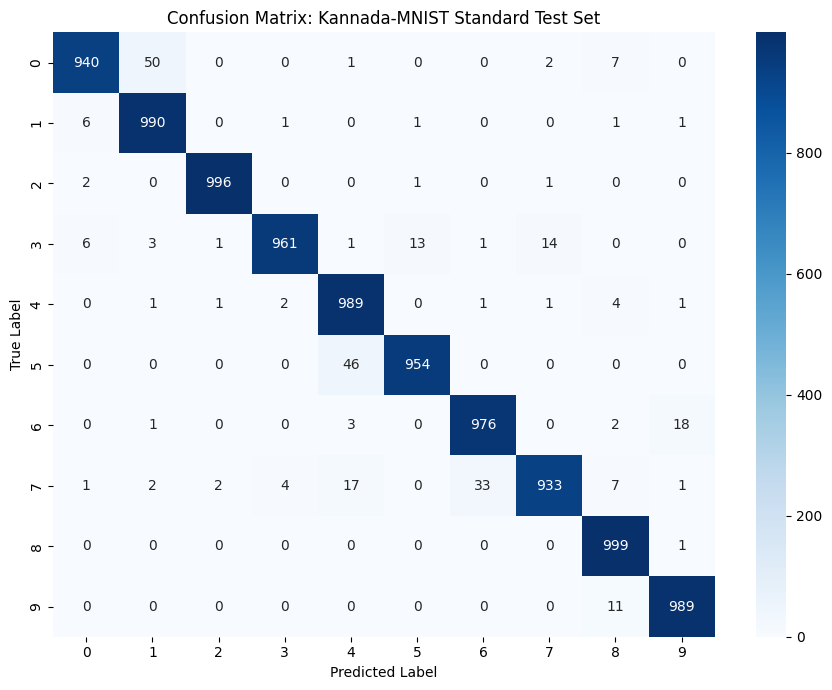

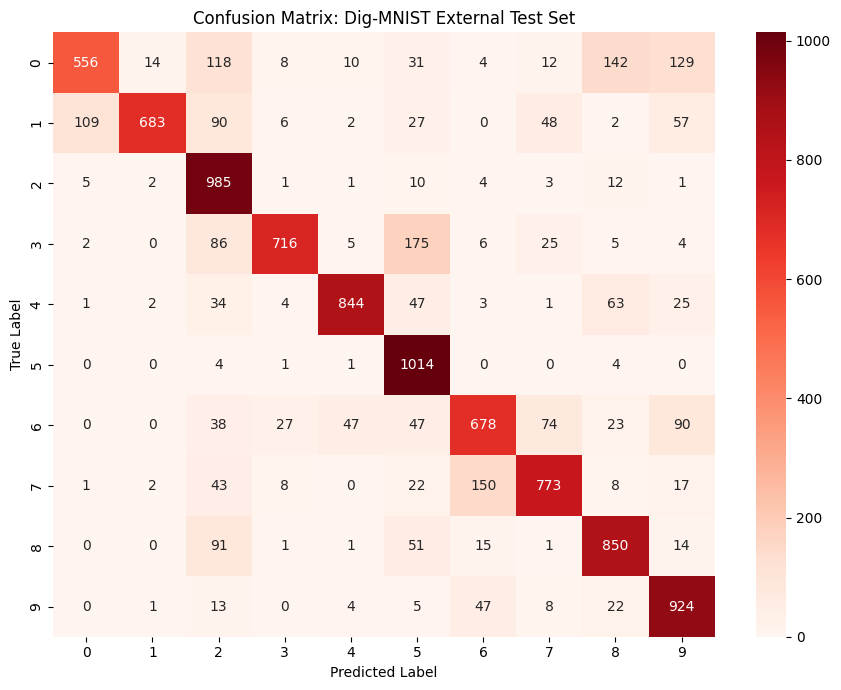

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Predictions on the standard test set
y_pred_test = np.argmax(best_model.predict(X_test, verbose=0), axis=1)

# Predictions on Dig-MNIST
y_pred_dig = np.argmax(best_model.predict(X_dig, verbose=0), axis=1)

# Standard-test confusion matrix
cm_test = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)
plt.title("Confusion Matrix: Kannada-MNIST Standard Test Set")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/confusion_matrix_standard_test.png", dpi=300)
plt.show()

# Dig-MNIST confusion matrix
cm_dig = confusion_matrix(y_dig, y_pred_dig)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_dig,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=range(10),
    yticklabels=range(10)
)
plt.title("Confusion Matrix: Dig-MNIST External Test Set")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/confusion_matrix_dig_mnist.png", dpi=300)
plt.show()

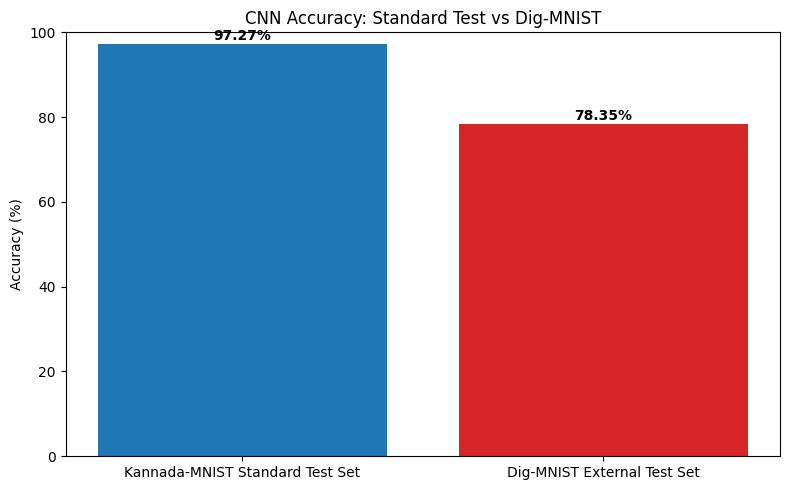

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    results["Dataset"],
    results["Accuracy (%)"],
    color=["#1f77b4", "#d62728"]
)

plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("CNN Accuracy: Standard Test vs Dig-MNIST")

for bar, value in zip(bars, results["Accuracy (%)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/accuracy_comparison.png", dpi=300)
plt.show()

Number of incorrect Dig-MNIST predictions: 2217


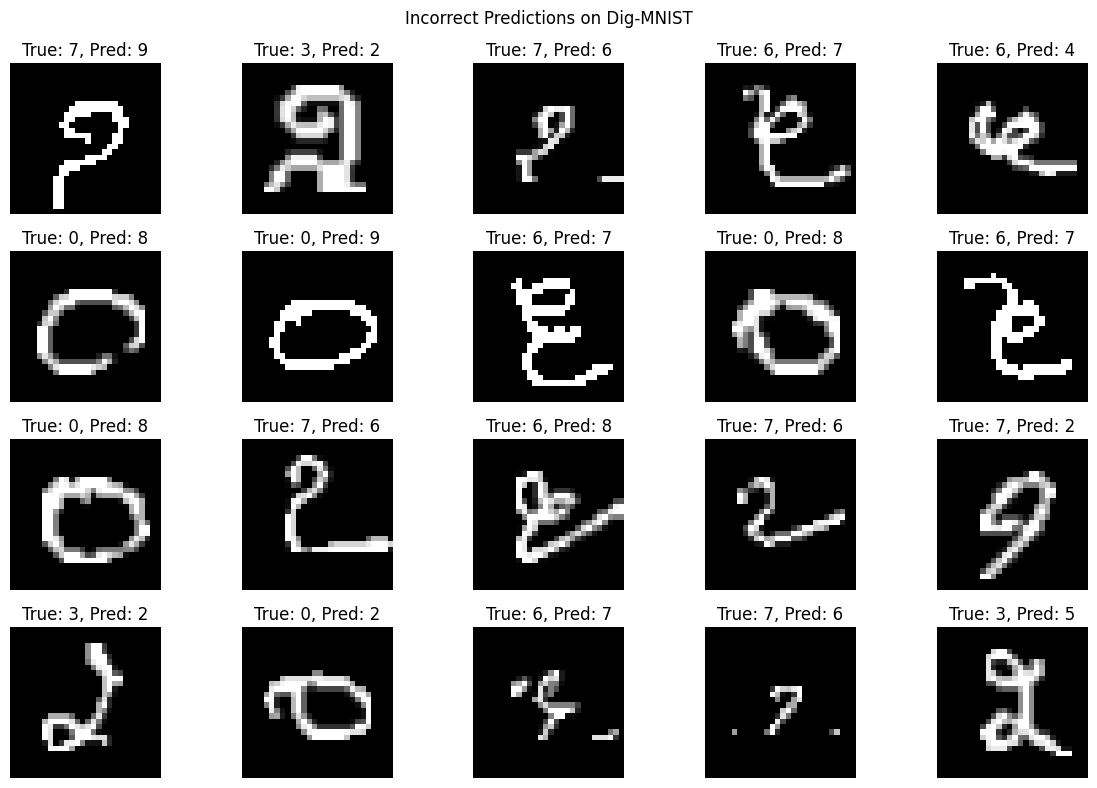

In [ ]:
wrong_indices = np.where(y_pred_dig != y_dig)[0]

print("Number of incorrect Dig-MNIST predictions:", len(wrong_indices))

plt.figure(figsize=(12, 8))

for i, idx in enumerate(wrong_indices[:20]):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X_dig[idx].squeeze(), cmap="gray")
    plt.title(f"True: {y_dig[idx]}, Pred: {y_pred_dig[idx]}")
    plt.axis("off")

plt.suptitle("Incorrect Predictions on Dig-MNIST")
plt.tight_layout()

plt.savefig(f"{PROJECT_DIR}/dig_mnist_errors.png", dpi=300)
plt.show()

In [ ]:
!ls -lh "$PROJECT_DIR"

total 3.5M
-rw------- 1 root root  92K Oct 23 06:30 accuracy_comparison.png
-rw------- 1 root root 2.9M Oct 23 06:22 best_kannada_cnn.keras
-rw------- 1 root root 208K Oct 23 06:29 confusion_matrix_dig_mnist.png
-rw------- 1 root root 165K Oct 23 06:29 confusion_matrix_standard_test.png
-rw------- 1 root root 132K Oct 23 06:31 dig_mnist_errors.png
-rw------- 1 root root  160 Oct 23 06:28 final_results.csv
-rw------- 1 root root  64K Oct 23 06:18 sample_training_images.png


In [ ]:
import os

model_file = f"{PROJECT_DIR}/best_kannada_cnn.keras"

print("Model exists:", os.path.exists(model_file))
print("Model size (MB):", round(os.path.getsize(model_file) / (1024 * 1024), 2))

Model exists: True
Model size (MB): 2.84
